In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 


In [50]:
df = pd.read_csv("AirQualityUCI.csv", sep=";", decimal=",")

df = df.dropna(axis=1, how="all")

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)
df.head()

Dataset loaded successfully
Rows and columns: (9471, 16)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN


In [51]:
# In this dataset, -200 means a missing sensor reading
df = df.replace(-200, np.nan)

df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y", errors="coerce")
df["Time"] = df["Time"].astype(str).str.replace(".", ":", regex=False)
df["DateTime"] = pd.to_datetime(
    df["Date"].dt.strftime("%d/%m/%Y") + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S", errors="coerce"
)

df = df.dropna(subset=["DateTime"]).copy()
df["YearMonth"] = df["DateTime"].dt.to_period("M").astype(str)
df["Hour"] = df["DateTime"].dt.hour

for col in df.columns:
    if col not in ["Date", "Time", "DateTime", "YearMonth"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Cleaned data:", df.shape)
df.head()


Cleaned data: (9357, 19)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 16,DateTime,YearMonth,Hour
0,2004-03-10,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,2004-03-10 18:00:00,2004-03,18
1,2004-03-10,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,2004-03-10 19:00:00,2004-03,19
2,2004-03-10,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,2004-03-10 20:00:00,2004-03,20
3,2004-03-10,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,2004-03-10 21:00:00,2004-03,21
4,2004-03-10,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,2004-03-10 22:00:00,2004-03,22


In [52]:
print("Column names:")
print(df.columns)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nBasic statistics:")
df[["CO(GT)", "NO2(GT)", "NOx(GT)"]].describe()

Column names:
Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
       'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 16', 'DateTime', 'YearMonth',
       'Hour'],
      dtype='str')

Missing values in each column:
Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
Unnamed: 16      9357
DateTime            0
YearMonth           0
Hour                0
dtype: int64

Basic statistics:


,CO(GT),NO2(GT),NOx(GT)
count,7674.000000,7715.000000,7718.000000
mean,2.152750,113.091251,246.896735
std,1.453252,48.370108,212.979168
min,0.100000,2.000000,2.000000
25%,1.100000,78.000000,98.000000
50%,1.800000,109.000000,180.000000
75%,2.900000,142.000000,326.000000
max,11.900000,340.000000,1479.000000


In [53]:
# Find monthly average for CO, NO2 and NOx
monthly_data = df.groupby("YearMonth")[["CO(GT)", "NO2(GT)", "NOx(GT)"]].mean()
monthly_data.head()

,CO(GT),NO2(GT),NOx(GT)
YearMonth,,,
2004-03,2.292073,102.581967,143.493852
2004-04,2.303838,96.880658,140.279835
2004-05,1.940034,93.148829,122.132107
2004-06,1.900000,94.084877,122.064715
2004-07,1.784946,104.120956,126.754213


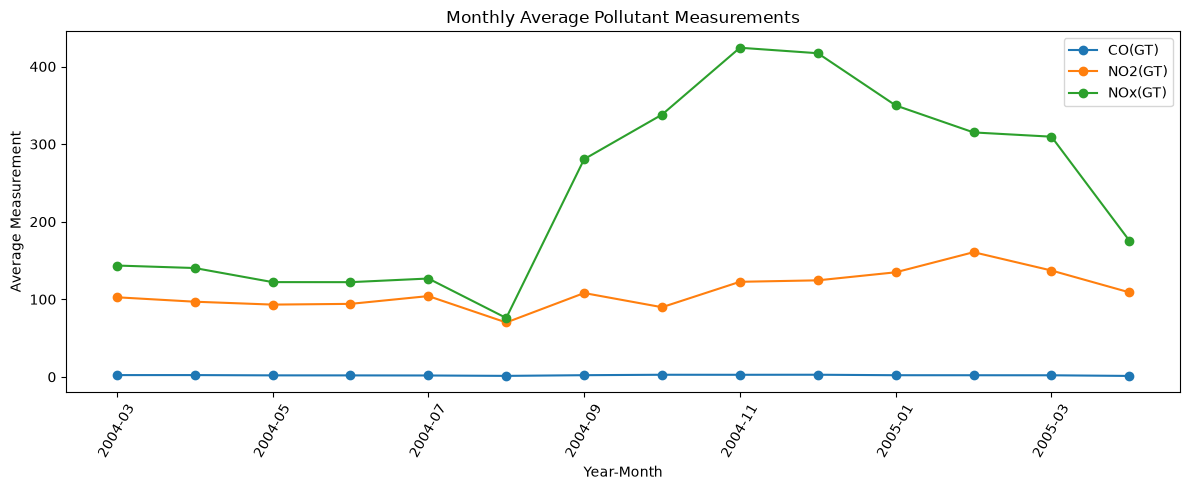

In [54]:
monthly_data.plot(kind="line", marker="o", figsize=(12, 5))
plt.title("Monthly Average Pollutant Measurements")
plt.xlabel("Year-Month")
plt.ylabel("Average Measurement")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [55]:
# Find average readings for each hour of the day
hourly_data = df.groupby("Hour")[["CO(GT)", "NO2(GT)"]].mean()
hourly_data

,CO(GT),NO2(GT)
Hour,,
0,1.786018,103.321429
1,1.467802,90.502994
2,1.099063,75.436747
3,0.888462,80.115385
4,0.758659,58.620482
5,0.712934,59.612613
6,0.921562,71.742515
7,1.810903,94.709581
8,2.823750,121.268293


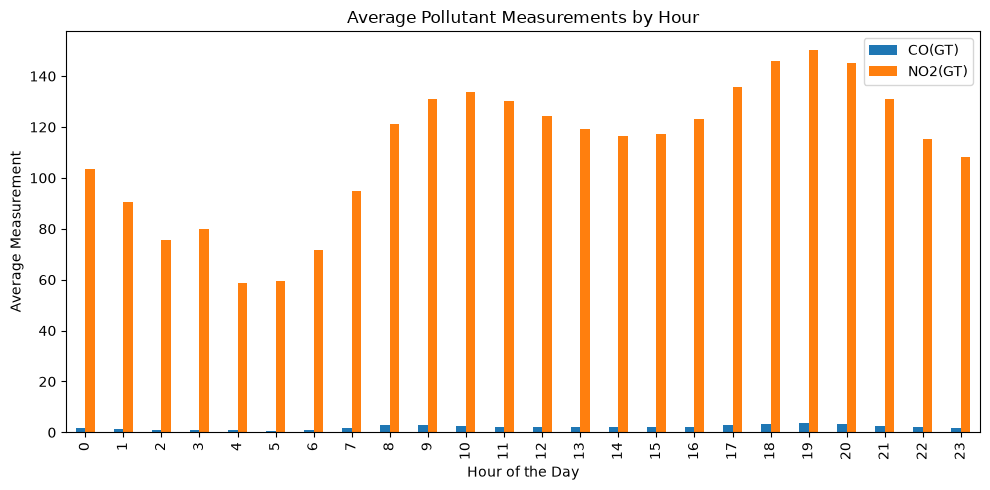

In [56]:
hourly_data.plot(kind="bar", figsize=(10, 5))
plt.title("Average Pollutant Measurements by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Measurement")
plt.tight_layout()
plt.show()

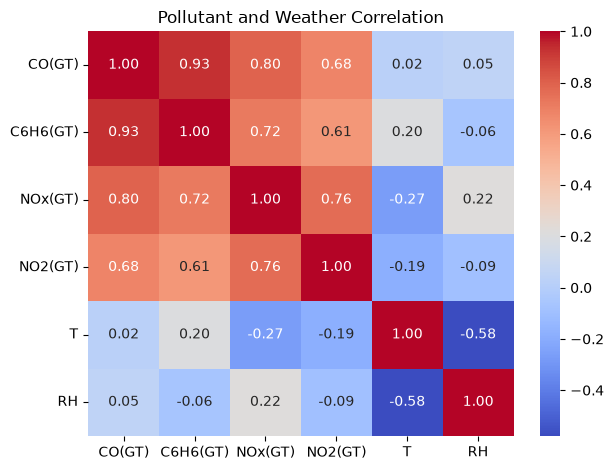

In [57]:
columns = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)", "T", "RH"]
correlation = df[columns].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Pollutant and Weather Correlation")
plt.tight_layout()
plt.show()